### 1. Загрузка данных

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target
print('Размер данных:', X.shape)
print('Классы:', {str(name): int(n) for name, n in zip(data.target_names, np.bincount(y))})

Размер данных: (569, 30)
Классы: {'malignant': 212, 'benign': 357}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

def fit_and_score(X_tr, X_te, n_runs=5):
    times = []
    for _ in range(n_runs):
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        start = time.time()
        model.fit(X_tr, y_train)
        times.append(time.time() - start)
    return accuracy_score(y_test, model.predict(X_te)), np.mean(times)

acc_raw, time_raw = fit_and_score(X_train, X_test)
print('Признаков:', X_train.shape[1])
print('Accuracy:', round(acc_raw, 4))
print('Время обучения, с:', round(time_raw, 3))

Признаков: 30
Accuracy: 0.9561
Время обучения, с: 0.388


Число компонент после PCA: 10
Доля сохранённой дисперсии: 0.9527


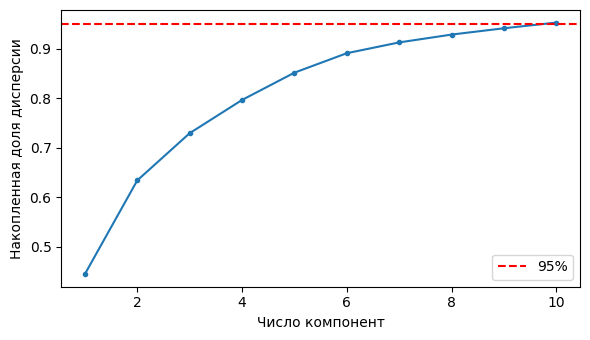

In [3]:
scaler = StandardScaler().fit(X_train)
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

pca = PCA(n_components=0.95).fit(X_train_sc)
X_train_pca = pca.transform(X_train_sc)
X_test_pca = pca.transform(X_test_sc)

print('Число компонент после PCA:', pca.n_components_)
print('Доля сохранённой дисперсии:', round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.xlabel('Число компонент')
plt.ylabel('Накопленная доля дисперсии')
plt.legend()
plt.tight_layout()
plt.show()

### 4. RandomForest на сжатых признаках

In [4]:
acc_pca, time_pca = fit_and_score(X_train_pca, X_test_pca)

comparison = pd.DataFrame({
    'Признаков': [X_train.shape[1], X_train_pca.shape[1]],
    'Accuracy (test)': [acc_raw, acc_pca],
    'Время обучения, с': [time_raw, time_pca],
}, index=['Исходные признаки', 'PCA (95% дисперсии)'])
print(comparison.round(4).to_string())

print()
print('Падение accuracy:', round((acc_raw - acc_pca) * 100, 2), 'п.п.')
print('Это', round((acc_raw - acc_pca) * len(y_test)), 'объекта(ов) из', len(y_test), 'в тестовой выборке')

                     Признаков  Accuracy (test)  Время обучения, с
Исходные признаки           30           0.9561             0.3882
PCA (95% дисперсии)         10           0.9211             0.3717

Падение accuracy: 3.51 п.п.
Это 4 объекта(ов) из 114 в тестовой выборке


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_raw = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=cv)
cv_pca = cross_val_score(
    make_pipeline(StandardScaler(), PCA(n_components=0.95), RandomForestClassifier(n_estimators=100, random_state=42)),
    X, y, cv=cv,
)

print('Исходные признаки: accuracy = %.4f ± %.4f' % (cv_raw.mean(), cv_raw.std()))
print('PCA (95%%):         accuracy = %.4f ± %.4f' % (cv_pca.mean(), cv_pca.std()))
print('Разница:', round((cv_raw.mean() - cv_pca.mean()) * 100, 2), 'п.п.')

Исходные признаки: accuracy = 0.9561 ± 0.0123
PCA (95%):         accuracy = 0.9508 ± 0.0251
Разница: 0.53 п.п.


In [6]:
%pip install umap-learn --quiet

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


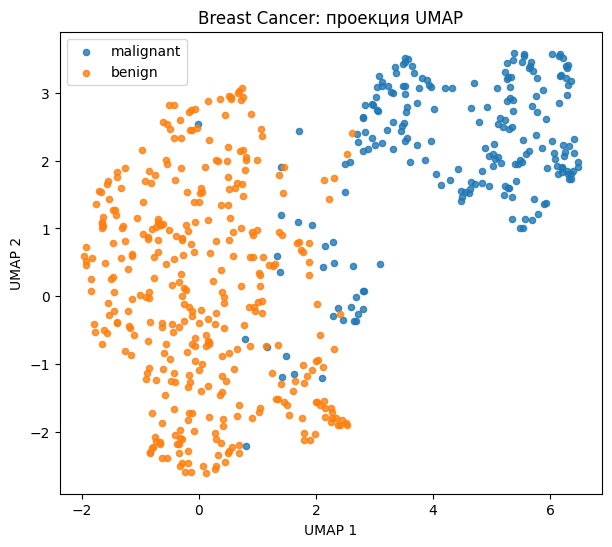

In [7]:
import umap

X_all_scaled = StandardScaler().fit_transform(X)
X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X_all_scaled)

plt.figure(figsize=(7, 6))
for cls, name in enumerate(data.target_names):
    mask = y == cls
    plt.scatter(X_umap[mask, 0], X_umap[mask, 1], label=name, s=20, alpha=0.8)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('Breast Cancer: проекция UMAP')
plt.legend()
plt.show()